# Loading And Validating Data

In [28]:
import numpy as np
import pandas as pd

DATA = "../Data/Processed"
ID_COL = "Customer ID"

train = pd.read_csv(f"{DATA}/train.csv")
test = pd.read_csv(f"{DATA}/test.csv")
train["split"] = "train"
test["split"] = "test"

full = pd.concat([train, test], ignore_index=True)
eff = pd.read_csv(f"{DATA}/effects_forestdr.csv")

# checks before merging
assert full[ID_COL].is_unique, "duplicate Customer IDs in train+test"
assert eff[ID_COL].is_unique, "duplicate Customer IDs in effects file"
assert len(full) == len(eff), f"row mismatch: {len(full)} vs {len(eff)}"
assert set(full[ID_COL]) == set(eff[ID_COL]), "IDs differ between data and effects"

df = full.merge(eff, on=ID_COL, how="left", validate="one_to_one")

# checks after merging
assert len(df) == len(full)
assert df[["ite_mens", "ite_womens"]].notna().all().all(), "NaNs after merge"

print("shape:", df.shape)
print(df[["ite_mens", "ite_womens"]].describe().round(4))

shape: (64000, 16)
         ite_mens  ite_womens
count  64000.0000  64000.0000
mean       0.0068      0.0032
std        0.0033      0.0035
min       -0.0030     -0.0106
25%        0.0044      0.0009
50%        0.0064      0.0030
75%        0.0089      0.0053
max        0.0214      0.0159


# Checking the effects against the audit

In [29]:
audit = pd.read_csv("../Reports/causal_audit/audit_summary.csv").set_index("treatment")

CONTROL = "No E-Mail"
ARMS = {"Mens E-Mail": "ite_mens", "Womens E-Mail": "ite_womens"}

conv = df.groupby("segment")["conversion"].mean()
rows = []

for arm, col in ARMS.items():
    a = audit.loc[arm]
    raw_ate = conv[arm] - conv[CONTROL]
    lo, hi = a["raw_CI_low_pp"] / 100, a["raw_CI_high_pp"] / 100
    mean_ite = df[col].mean()

    # 1. merged data reproduces the audit 
    assert abs(raw_ate - a["raw_ATE"]) < 1e-5, f"{arm}: recomputed ATE differs from audit"
    # 2. mean predicted effect sits inside the audit confidence interval
    assert lo <= mean_ite <= hi, f"{arm}: mean ITE {mean_ite:.4f} outside audit CI ({lo:.4f}, {hi:.4f})"
    # 4. no absurd values
    assert df[col].abs().max() < 0.05, f"{arm}: effect larger than 5 pp"

    rows.append({
        "arm": arm,
        "audit ATE (pp)": a["raw_ATE"] * 100,
        "recomputed ATE (pp)": raw_ate * 100,
        "audit CI low (pp)": lo * 100,
        "audit CI high (pp)": hi * 100,
        "mean ITE all (pp)": mean_ite * 100,
        "mean ITE train (pp)": df.loc[df["split"] == "train", col].mean() * 100,
        "mean ITE test (pp)": df.loc[df["split"] == "test", col].mean() * 100,
        "ITE std (pp)": df[col].std() * 100,
        "min ITE (pp)": df[col].min() * 100,
        "max ITE (pp)": df[col].max() * 100,
        "share ITE < 0": (df[col] < 0).mean(),
    })

check = pd.DataFrame(rows).round(3).set_index("arm").T
display(check)
print("Audit check passed: effects are consistent with the audit.")

arm,Mens E-Mail,Womens E-Mail
audit ATE (pp),0.681,0.311
recomputed ATE (pp),0.681,0.311
audit CI low (pp),0.500,0.150
audit CI high (pp),0.861,0.472
mean ITE all (pp),0.682,0.317
mean ITE train (pp),0.683,0.317
mean ITE test (pp),0.678,0.318
ITE std (pp),0.332,0.346
min ITE (pp),-0.296,-1.062
max ITE (pp),2.139,1.594


Audit check passed: effects are consistent with the audit.


# Setting the revenue value of a conversion

In [30]:
# 1-2. train converters only
conv_train = df[(df["split"] == "train") & (df["conversion"] == 1)]
assert (conv_train["spend"] > 0).all(), "some converters have spend <= 0"

# 3. value of one conversion
VALUE_PER_CONV = conv_train["spend"].mean()

print(f"converters in train : {len(conv_train)}")
print(f"mean spend (USED)   : {VALUE_PER_CONV:.2f}")
print(f"median spend        : {conv_train['spend'].median():.2f}")

# 4. per-arm check only
print("\nPer-arm check (not used):")
print(conv_train.groupby("segment")["spend"].agg(["count", "mean", "median"]).round(2))

# 5. expected incremental revenue per customer
df["rev_mens"] = df["ite_mens"] * VALUE_PER_CONV
df["rev_womens"] = df["ite_womens"] * VALUE_PER_CONV

# 6. sanity check
print("\nExpected revenue gain per e-mail sent (break-even cost):")
print(df[["rev_mens", "rev_womens"]].mean().round(4))
print("\nShare of customers with negative revenue effect:")
print((df[["rev_mens", "rev_womens"]] < 0).mean().round(3))

assert np.isclose(df["rev_mens"].mean(), df["ite_mens"].mean() * VALUE_PER_CONV)
assert np.isclose(df["rev_womens"].mean(), df["ite_womens"].mean() * VALUE_PER_CONV)
print("\nRevenue value set.")

converters in train : 463
mean spend (USED)   : 113.83
median spend        : 76.16

Per-arm check (not used):
               count    mean  median
segment                             
Mens E-Mail      214  115.39   66.30
No E-Mail         98  104.97   80.97
Womens E-Mail    151  117.37   87.82

Expected revenue gain per e-mail sent (break-even cost):
rev_mens      0.7762
rev_womens    0.3611
dtype: float64

Share of customers with negative revenue effect:
rev_mens      0.005
rev_womens    0.168
dtype: float64

Revenue value set.


# Setting the email costs and the budget

In [31]:
# ASSUMED costs per e-mail (dollars); replace with real costs
COST = {"Mens E-Mail": 0.10, "Womens E-Mail": 0.15}   # dollars per e-mail sent
BUDGET_SHARES = [0.10, 0.25, 0.50]
MAIN_SHARE = 0.25

assert all(c > 0 for c in COST.values()), "costs must be positive"

n = len(df)
be = {"Mens E-Mail": df["rev_mens"].mean(), "Womens E-Mail": df["rev_womens"].mean()}

print("Cost vs break-even (average extra revenue per e-mail):")
for arm in COST:
    flag = "OK" if COST[arm] < be[arm] else "ABOVE BREAK-EVEN"
    print(f"  {arm:14s} cost {COST[arm]:.3f}  break-even {be[arm]:.3f}  -> {flag}")

# 2. unconstrained spend: best arm per customer, only if net value > 0
net_m = df["rev_mens"] - COST["Mens E-Mail"]
net_w = df["rev_womens"] - COST["Womens E-Mail"]
best_is_mens = net_m >= net_w
best_net = np.maximum(net_m, net_w)
send = best_net > 0
unc_cost = np.where(best_is_mens, COST["Mens E-Mail"], COST["Womens E-Mail"])[send].sum()
print(f"\nUnconstrained: {send.sum():,} of {n:,} customers worth e-mailing, "
      f"spend ${unc_cost:,.0f}")

# 3-4. budget scenarios and binding check
full_cost = n * min(COST.values())
rows = []
for s in BUDGET_SHARES:
    B = s * full_cost
    rows.append({
        "share of full cost": s,
        "budget B ($)": round(B, 2),
        "max e-mails (cheapest arm)": int(B // min(COST.values())),
        "binds?": B < unc_cost,
    })
budgets = pd.DataFrame(rows)
display(budgets)
assert budgets.loc[budgets["share of full cost"] == MAIN_SHARE, "binds?"].item(), \
    "main budget does not bind: lower MAIN_SHARE or raise the costs"

# 5. one parameter block, saved in step 7
PARAMS = {
    "COST": COST,
    "VALUE_PER_CONV": VALUE_PER_CONV,
    "BUDGET": MAIN_SHARE * full_cost,
    "BUDGET_SHARES": BUDGET_SHARES,
}
print("\nBudget used in the main run:", round(PARAMS["BUDGET"], 2))
print("Costs and budget set.")

Cost vs break-even (average extra revenue per e-mail):
  Mens E-Mail    cost 0.100  break-even 0.776  -> OK
  Womens E-Mail  cost 0.150  break-even 0.361  -> OK

Unconstrained: 63,606 of 64,000 customers worth e-mailing, spend $6,882


,share of full cost,budget B ($),max e-mails (cheapest arm),binds?
0,0.10,640.0,6399,True
1,0.25,1600.0,15999,True
2,0.50,3200.0,31999,True



Budget used in the main run: 1600.0
Costs and budget set.


# Building the baselines

In [32]:
B = PARAMS["BUDGET"]
c_m, c_w = COST["Mens E-Mail"], COST["Womens E-Mail"]
rev_m = df["rev_mens"].to_numpy()
rev_w = df["rev_womens"].to_numpy()
n = len(df)

# 1-2. one format for every plan + one scoring function
def evaluate(assign, name, feasible=True):
    assign = np.asarray(assign)
    m, w = assign == "mens", assign == "womens"
    cost = m.sum() * c_m + w.sum() * c_w
    rev = rev_m[m].sum() + rev_w[w].sum()
    if feasible:
        assert cost <= B + 1e-6, f"{name}: cost {cost:.2f} exceeds budget {B:.2f}"
    return {"plan": name, "revenue ($)": rev, "cost ($)": cost,
            "mens e-mails": int(m.sum()), "womens e-mails": int(w.sum()),
            "revenue per $": rev / cost if cost > 0 else np.nan,
            "within budget": cost <= B + 1e-6}

plans = {}

# 3a. send nobody
plans["Send nobody"] = np.full(n, "none", dtype=object)

# 3b. random Mens until the budget runs out
rng = np.random.default_rng(42)
k = int(B // c_m)
a = np.full(n, "none", dtype=object)
a[rng.choice(n, size=k, replace=False)] = "mens"
plans["Random Mens"] = a

# 3c. top Mens by predicted revenue
a = np.full(n, "none", dtype=object)
a[np.argsort(-rev_m)[:k]] = "mens"
plans["Top Mens"] = a

# 3d. greedy best arm by revenue per dollar
ratio_m, ratio_w = rev_m / c_m, rev_w / c_w
use_m = ratio_m >= ratio_w
ratio = np.where(use_m, ratio_m, ratio_w)
cost_i = np.where(use_m, c_m, c_w)

order = np.argsort(-ratio)
order = order[ratio[order] > 0]
keep = order[np.cumsum(cost_i[order]) <= B]

a = np.full(n, "none", dtype=object)
a[keep] = np.where(use_m[keep], "mens", "womens")
plans["Greedy best arm"] = a

# 4. reference lines (not feasible under B)
plans["Everyone Mens (reference)"] = np.full(n, "mens", dtype=object)

net_m, net_w = rev_m - c_m, rev_w - c_w
best_mens = net_m >= net_w
best_net = np.maximum(net_m, net_w)
a = np.full(n, "none", dtype=object)
send = best_net > 0
a[send] = np.where(best_mens[send], "mens", "womens")
plans["Unconstrained best (reference)"] = a

# 5. results table
refs = ("Everyone Mens (reference)", "Unconstrained best (reference)")
results = pd.DataFrame([
    evaluate(v, k_, feasible=k_ not in refs) for k_, v in plans.items()
]).set_index("plan")

display(results.round(2))
print(f"Budget B = ${B:,.2f}")
print("Baselines built.")

,revenue ($),cost ($),mens e-mails,womens e-mails,revenue per $,within budget
plan,,,,,,
Send nobody,0.00,0.00,0,0,NaN,True
Random Mens,12427.44,1599.90,15999,0,7.77,True
Top Mens,20660.96,1599.90,15999,0,12.91,True
Greedy best arm,20664.94,1599.95,15929,47,12.92,True
Everyone Mens (reference),49677.13,6400.00,64000,0,7.76,False
Unconstrained best (reference),52621.20,6881.75,53183,10423,7.65,False


Budget B = $1,600.00
Baselines built.


# Saving the optimizer inputs

In [33]:
from pathlib import Path
import json

out = Path("../Data/Processed")

opt_inputs = df[[ID_COL, "split", "segment", "conversion",
                 "ite_mens", "ite_womens", "rev_mens", "rev_womens"]].copy()

assert opt_inputs[ID_COL].is_unique
assert opt_inputs.notna().all().all(), "NaNs in optimizer inputs"
assert len(opt_inputs) == len(df)

opt_inputs.to_csv(out / "optimizer_inputs.csv", index=False)

with open(out / "optimizer_params.json", "w") as f:
    json.dump({k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
               for k, v in PARAMS.items()}, f, indent=2)

print("saved:", opt_inputs.shape)
print(json.dumps(PARAMS, indent=2, default=float))
print("Optimizer inputs saved.")

saved: (64000, 8)
{
  "COST": {
    "Mens E-Mail": 0.1,
    "Womens E-Mail": 0.15
  },
  "VALUE_PER_CONV": 113.82876889848812,
  "BUDGET": 1600.0,
  "BUDGET_SHARES": [
    0.1,
    0.25,
    0.5
  ]
}
Optimizer inputs saved.


# Solving the LP and comparing

In [34]:
from scipy import sparse
from scipy.optimize import linprog

# 1-3. variables z = [x_mens (n), x_womens (n)], constraints in sparse form
I = sparse.identity(n, format="csr")
A_assign = sparse.hstack([I, I], format="csr")                 # x_m + x_w <= 1
A_budget = sparse.csr_matrix(np.concatenate([np.full(n, c_m), np.full(n, c_w)]))   # cost <= B
A_ub = sparse.vstack([A_budget, A_assign], format="csr")
b_ub = np.concatenate([[B], np.ones(n)])
c_obj = -np.concatenate([rev_m, rev_w])                        # maximize revenue

# 4. solve
res = linprog(c_obj, A_ub=A_ub, b_ub=b_ub, bounds=(0, 1), method="highs")

# 5. status
print("status:", res.status, "-", res.message)
assert res.status == 0, "solver did not find an optimal solution"

# 6. round: keep only values that are exactly 1, drop fractional customers
x_m, x_w = res.x[:n], res.x[n:]
tol = 1e-6
frac = ((x_m > tol) & (x_m < 1 - tol)) | ((x_w > tol) & (x_w < 1 - tol))
assign = np.where(x_m > 1 - tol, "mens", np.where(x_w > 1 - tol, "womens", "none"))
print("fractional customers dropped:", int(frac.sum()))

# 7. shadow price and LP upper bound
shadow = -res.ineqlin.marginals[0]
print(f"LP revenue (upper bound): ${-res.fun:,.2f}")
print(f"shadow price: ${shadow:.2f} of extra revenue per extra $1 of budget")

# 8. compare with the baselines
plans["LP optimizer"] = assign
compare = pd.DataFrame([
    evaluate(plans[k_], k_) for k_ in ["Top Mens", "Greedy best arm", "LP optimizer"]
]).set_index("plan")
display(compare.round(2))
print("LP solved.")

status: 0 - Optimization terminated successfully. (HiGHS Status 7: Optimal)
fractional customers dropped: 0
LP revenue (upper bound): $20,665.55
shadow price: $10.15 of extra revenue per extra $1 of budget


,revenue ($),cost ($),mens e-mails,womens e-mails,revenue per $,within budget
plan,,,,,,
Top Mens,20660.96,1599.90,15999,0,12.91,True
Greedy best arm,20664.94,1599.95,15929,47,12.92,True
LP optimizer,20665.55,1600.00,15922,52,12.92,True


LP solved.


# Budget curve

,budget B ($),cost ($),revenue ($),mens e-mails,womens e-mails,shadow price ($ per $),revenue per $
share of full cost,,,,,,,
0.05,320.0,320.0,5342.61,3200,0,14.52,16.70
0.10,640.0,640.0,9707.02,6400,0,12.91,15.17
0.25,1600.0,1600.0,20665.55,15922,52,10.15,12.92
0.50,3200.0,3200.0,34496.37,30992,672,7.39,10.78
0.75,4800.0,4800.0,44681.29,43974,2684,5.39,9.31
1.00,6400.0,6400.0,51583.13,53467,7022,2.98,8.06


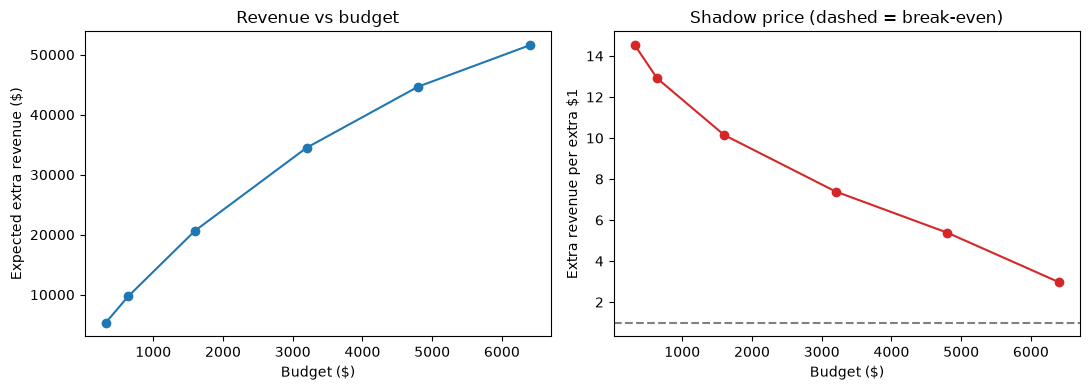

Budget curve built.


In [35]:
import matplotlib.pyplot as plt

def solve_lp(B_):
    b = np.concatenate([[B_], np.ones(n)])
    r = linprog(c_obj, A_ub=A_ub, b_ub=b, bounds=(0, 1), method="highs")
    assert r.status == 0, f"solver failed at B={B_}: {r.message}"
    xm, xw = r.x[:n], r.x[n:]
    tol = 1e-6
    m, w = xm > 1 - tol, xw > 1 - tol
    return {
        "budget B ($)": B_,
        "cost ($)": m.sum() * c_m + w.sum() * c_w,
        "revenue ($)": rev_m[m].sum() + rev_w[w].sum(),
        "mens e-mails": int(m.sum()),
        "womens e-mails": int(w.sum()),
        "shadow price ($ per $)": -r.ineqlin.marginals[0],
    }

shares = [0.05, 0.10, 0.25, 0.50, 0.75, 1.00]
rows = []
for s in shares:
    row = solve_lp(s * full_cost)
    row["share of full cost"] = s
    rows.append(row)

curve = pd.DataFrame(rows).set_index("share of full cost")
curve["revenue per $"] = curve["revenue ($)"] / curve["cost ($)"]
display(curve.round(2))

# the main budget must reproduce step 8
main = curve.loc[MAIN_SHARE, "revenue ($)"]
assert abs(main - compare.loc["LP optimizer", "revenue ($)"]) < 1.0, "main budget differs from step 7"

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(curve["budget B ($)"], curve["revenue ($)"], marker="o")
ax[0].set_xlabel("Budget ($)"); ax[0].set_ylabel("Expected extra revenue ($)")
ax[0].set_title("Revenue vs budget")
ax[1].plot(curve["budget B ($)"], curve["shadow price ($ per $)"], marker="o", color="tab:red")
ax[1].axhline(1, ls="--", color="gray")
ax[1].set_xlabel("Budget ($)"); ax[1].set_ylabel("Extra revenue per extra $1")
ax[1].set_title("Shadow price (dashed = break-even)")
plt.tight_layout(); plt.show()
print("Budget curve built.")

# Packaging the optimizer and save the plan


In [36]:
%%writefile ../Models/optimizer.py
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.optimize import linprog


def optimize_campaign(df, cost, budget, value_per_conv, tol=1e-6):
    """Assign each customer a Mens e-mail, a Womens e-mail or no e-mail.

    Maximises total expected extra revenue subject to total e-mail cost <= budget
    and at most one e-mail per customer.

    df              needs columns ite_mens and ite_womens (estimated increase in
                    purchase probability), plus any id columns you want to keep
    cost            {"Mens E-Mail": dollars, "Womens E-Mail": dollars}
    budget          total e-mail budget in dollars
    value_per_conv  average revenue of one conversion in dollars
    """
    c_m, c_w = cost["Mens E-Mail"], cost["Womens E-Mail"]
    n = len(df)
    rev_m = df["ite_mens"].to_numpy() * value_per_conv
    rev_w = df["ite_womens"].to_numpy() * value_per_conv

    ident = sparse.identity(n, format="csr")
    A_ub = sparse.vstack([
        sparse.csr_matrix(np.concatenate([np.full(n, c_m), np.full(n, c_w)])),  # total cost <= budget
        sparse.hstack([ident, ident], format="csr"),                            # one e-mail per customer
    ], format="csr")
    b_ub = np.concatenate([[budget], np.ones(n)])

    res = linprog(-np.concatenate([rev_m, rev_w]), A_ub=A_ub, b_ub=b_ub,
                  bounds=(0, 1), method="highs")
    if res.status != 0:
        raise RuntimeError(f"solver did not find an optimal solution: {res.message}")

    x_m, x_w = res.x[:n], res.x[n:]
    send_m, send_w = x_m > 1 - tol, x_w > 1 - tol
    fractional = ((x_m > tol) & (x_m < 1 - tol)) | ((x_w > tol) & (x_w < 1 - tol))

    assigned = np.where(send_m, "Mens E-Mail", np.where(send_w, "Womens E-Mail", "No E-Mail"))
    has_gain = (df["ite_mens"].to_numpy() > 0) | (df["ite_womens"].to_numpy() > 0)

    out = df.copy()
    out["assigned_arm"] = assigned
    out["expected_uplift"] = np.where(send_m, df["ite_mens"], np.where(send_w, df["ite_womens"], 0.0))
    out["expected_revenue"] = np.where(send_m, rev_m, np.where(send_w, rev_w, 0.0))
    out["cost"] = np.where(send_m, c_m, np.where(send_w, c_w, 0.0))
    out["group"] = np.where(assigned != "No E-Mail", "Persuadable",
                            np.where(has_gain, "Not selected (budget)", "No positive uplift"))

    summary = {
        "budget": float(budget),
        "total_cost": float(out["cost"].sum()),
        "total_expected_revenue": float(out["expected_revenue"].sum()),
        "mens_emails": int(send_m.sum()),
        "womens_emails": int(send_w.sum()),
        "shadow_price": float(-res.ineqlin.marginals[0]),
        "fractional_dropped": int(fractional.sum()),
    }
    return out, summary

Overwriting ../Models/optimizer.py


In [37]:
import sys, importlib
sys.path.insert(0, "../Models")
import optimizer
importlib.reload(optimizer)          # picks up the file if you edit it later
from optimizer import optimize_campaign

plan, summary = optimize_campaign(
    df, PARAMS["COST"], PARAMS["BUDGET"], PARAMS["VALUE_PER_CONV"]
)
print(summary)

# must match step 8
assert abs(summary["total_expected_revenue"] - compare.loc["LP optimizer", "revenue ($)"]) < 1.0
assert summary["total_cost"] <= PARAMS["BUDGET"] + 1e-6

print("\n", plan["group"].value_counts().to_string())

keep = [ID_COL, "split", "ite_mens", "ite_womens", "assigned_arm",
        "expected_uplift", "expected_revenue", "cost", "group"]
plan[keep].to_csv("../Data/Processed/optimal_plan.csv", index=False)
print("\nsaved optimal_plan.csv:", plan[keep].shape)
print("Plan saved.")

{'budget': 1600.0, 'total_cost': 1600.0, 'total_expected_revenue': 20665.554599736148, 'mens_emails': 15922, 'womens_emails': 52, 'shadow_price': 10.149981883219516, 'fractional_dropped': 0}

 group
Not selected (budget)    47941
Persuadable              15974
No positive uplift          85

saved optimal_plan.csv: (64000, 9)
Plan saved.


# Robustness checking

In [38]:
# inputs for the scenarios
audit = pd.read_csv("../Reports/causal_audit/audit_summary.csv").set_index("treatment")

cf = pd.read_csv("../Data/Processed/effects_causalforest.csv")
cf = df[[ID_COL]].merge(cf, on=ID_COL, how="left", validate="one_to_one")   # same row order as df
assert cf[["ite_mens", "ite_womens"]].notna().all().all(), "NaNs in CausalForest effects"

V = PARAMS["VALUE_PER_CONV"]
MEDIAN_VALUE = conv_train["spend"].median()

# shrink factor = audit CI lower bound / audit ATE
shrink = {
    "ite_mens":   audit.loc["Mens E-Mail", "raw_CI_low_pp"] / 100 / audit.loc["Mens E-Mail", "raw_ATE"],
    "ite_womens": audit.loc["Womens E-Mail", "raw_CI_low_pp"] / 100 / audit.loc["Womens E-Mail", "raw_ATE"],
}
print("shrink factors:", {k: round(v, 3) for k, v in shrink.items()})

base_eff = df[["ite_mens", "ite_womens"]].reset_index(drop=True)
cf_eff = cf[["ite_mens", "ite_womens"]].reset_index(drop=True)

scenarios = {
    "Pessimistic effects (audit CI low)": (
        base_eff.assign(ite_mens=base_eff["ite_mens"] * shrink["ite_mens"],
                        ite_womens=base_eff["ite_womens"] * shrink["ite_womens"]), V),
    "Two-forest average": ((base_eff + cf_eff) / 2, V),
    "Median spend value": (base_eff, MEDIAN_VALUE),
}

def revenue_of(assigned, eff, v):
    a = np.asarray(assigned)
    m, w = a == "Mens E-Mail", a == "Womens E-Mail"
    return (eff["ite_mens"].to_numpy()[m].sum() + eff["ite_womens"].to_numpy()[w].sum()) * v

base_assign = plan["assigned_arm"].to_numpy()
base_sel = base_assign != "No E-Mail"

rows = [{
    "scenario": "Base (ForestDR, mean spend)",
    "optimal revenue ($)": summary["total_expected_revenue"],
    "base plan revenue ($)": summary["total_expected_revenue"],
    "regret (%)": 0.0,
    "mens e-mails": summary["mens_emails"],
    "womens e-mails": summary["womens_emails"],
    "base customers kept (%)": 100.0,
    "shadow price": summary["shadow_price"],
}]

for name, (eff, v) in scenarios.items():
    d = eff.copy()
    d[ID_COL] = df[ID_COL].values
    p, s = optimize_campaign(d, PARAMS["COST"], PARAMS["BUDGET"], v)
    own = s["total_expected_revenue"]
    base_under = revenue_of(base_assign, eff, v)
    sel = p["assigned_arm"].to_numpy() != "No E-Mail"
    rows.append({
        "scenario": name,
        "optimal revenue ($)": own,
        "base plan revenue ($)": base_under,
        "regret (%)": 100 * (own - base_under) / own,
        "mens e-mails": s["mens_emails"],
        "womens e-mails": s["womens_emails"],
        "base customers kept (%)": 100 * (sel & base_sel).sum() / base_sel.sum(),
        "shadow price": s["shadow_price"],
    })

robust = pd.DataFrame(rows).set_index("scenario")
display(robust.round(2))
print("Robustness checks done.")

shrink factors: {'ite_mens': np.float64(0.735), 'ite_womens': np.float64(0.482)}


,optimal revenue ($),base plan revenue ($),regret (%),mens e-mails,womens e-mails,base customers kept (%),shadow price
scenario,,,,,,,
"Base (ForestDR, mean spend)",20665.55,20665.55,0.00,15922,52,100.00,10.15
Pessimistic effects (audit CI low),15181.87,15163.36,0.12,16000,0,99.75,7.45
Two-forest average,20546.30,20470.22,0.37,15949,34,93.44,10.11
Median spend value,13826.81,13826.81,-0.00,15922,52,100.00,6.79


Robustness checks done.


# Validating against Real Customer

## Outcome: real spend

In [39]:
# plans from baseline, use "mens"/"womens"/"none"; the optimizer plan already uses full names'
# Outcome: real spend
NAME = {"mens": "Mens E-Mail", "womens": "Womens E-Mail", "none": "No E-Mail"}
policies = {
    "LP optimizer": plan["assigned_arm"].to_numpy(),
    "Top Mens": np.array([NAME[x] for x in plans["Top Mens"]]),
    "Random Mens": np.array([NAME[x] for x in plans["Random Mens"]]),
}

seg = df["segment"].to_numpy()
y = df["spend"].to_numpy()
share = df["segment"].value_counts(normalize=True)
print("arm shares (should be about 1/3 each):", share.round(3).to_dict())
w = 1 / df["segment"].map(share).to_numpy()
is_ctrl = seg == "No E-Mail"

# per-customer contribution to incremental revenue vs "send nobody"
contrib, pred, cost = {}, {}, {}
for name, a in policies.items():
    contrib[name] = ((seg == a).astype(float) - is_ctrl) * y * w
    pred[name] = np.where(a == "Mens E-Mail", rev_m,
                          np.where(a == "Womens E-Mail", rev_w, 0.0)).sum()
    cost[name] = ((a == "Mens E-Mail").sum() * COST["Mens E-Mail"]
                  + (a == "Womens E-Mail").sum() * COST["Womens E-Mail"])

names = list(policies)
C = np.column_stack([contrib[k] for k in names])
point = C.sum(axis=0)

# bootstrap customers (same resamples for every plan, so differences are paired)
rng = np.random.default_rng(42)
n_ = len(df)
boots = np.empty((1000, len(names)))
for b in range(1000):
    idx = rng.integers(0, n_, n_)
    boots[b] = C[idx].sum(axis=0)
lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)

ipw_table = pd.DataFrame({
    "predicted incremental revenue ($)": [pred[k] for k in names],
    "IPW incremental revenue ($)": point,
    "95% CI low": lo,
    "95% CI high": hi,
    "cost ($)": [cost[k] for k in names],
}, index=names)
ipw_table["IPW net of cost ($)"] = ipw_table["IPW incremental revenue ($)"] - ipw_table["cost ($)"]
display(ipw_table.round(0))
ipw_spend = ipw_table.copy()
# does ranking by uplift beat random targeting?
i_lp, i_rand = names.index("LP optimizer"), names.index("Random Mens")
d_point = point[i_lp] - point[i_rand]
d_lo, d_hi = np.percentile(boots[:, i_lp] - boots[:, i_rand], [2.5, 97.5])
print(f"LP optimizer minus Random Mens: ${d_point:,.0f}  (95% CI ${d_lo:,.0f} to ${d_hi:,.0f})")
print("IPW validation (spend) done.")

arm shares (should be about 1/3 each): {'Womens E-Mail': 0.334, 'Mens E-Mail': 0.333, 'No E-Mail': 0.333}


,predicted incremental revenue ($),IPW incremental revenue ($),95% CI low,95% CI high,cost ($),IPW net of cost ($)
LP optimizer,20666.0,11224.0,2035.0,21713.0,1600.0,9624.0
Top Mens,20661.0,10734.0,1610.0,21390.0,1600.0,9134.0
Random Mens,12427.0,15518.0,6172.0,26176.0,1600.0,13918.0


LP optimizer minus Random Mens: $-4,294  (95% CI $-16,494 to $5,818)
IPW validation (spend) done.


## Outcome: conversion x value per conversion

In [40]:
# plans from baseline, use "mens"/"womens"/"none"; the optimizer plan already uses full names'
# Outcome: conversion x value per conversion
NAME = {"mens": "Mens E-Mail", "womens": "Womens E-Mail", "none": "No E-Mail"}
policies = {
    "LP optimizer": plan["assigned_arm"].to_numpy(),
    "Top Mens": np.array([NAME[x] for x in plans["Top Mens"]]),
    "Random Mens": np.array([NAME[x] for x in plans["Random Mens"]]),
}

seg = df["segment"].to_numpy()
y = df["conversion"].to_numpy() * PARAMS["VALUE_PER_CONV"]
share = df["segment"].value_counts(normalize=True)
print("arm shares (should be about 1/3 each):", share.round(3).to_dict())
w = 1 / df["segment"].map(share).to_numpy()
is_ctrl = seg == "No E-Mail"

# per-customer contribution to incremental revenue vs "send nobody"
contrib, pred, cost = {}, {}, {}
for name, a in policies.items():
    contrib[name] = ((seg == a).astype(float) - is_ctrl) * y * w
    pred[name] = np.where(a == "Mens E-Mail", rev_m,
                          np.where(a == "Womens E-Mail", rev_w, 0.0)).sum()
    cost[name] = ((a == "Mens E-Mail").sum() * COST["Mens E-Mail"]
                  + (a == "Womens E-Mail").sum() * COST["Womens E-Mail"])

names = list(policies)
C = np.column_stack([contrib[k] for k in names])
point = C.sum(axis=0)

# bootstrap customers (same resamples for every plan, so differences are paired)
rng = np.random.default_rng(42)
n_ = len(df)
boots = np.empty((1000, len(names)))
for b in range(1000):
    idx = rng.integers(0, n_, n_)
    boots[b] = C[idx].sum(axis=0)
lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)

ipw_table = pd.DataFrame({
    "predicted incremental revenue ($)": [pred[k] for k in names],
    "IPW incremental revenue ($)": point,
    "95% CI low": lo,
    "95% CI high": hi,
    "cost ($)": [cost[k] for k in names],
}, index=names)
ipw_table["IPW net of cost ($)"] = ipw_table["IPW incremental revenue ($)"] - ipw_table["cost ($)"]
display(ipw_table.round(0))
# does ranking by uplift beat random targeting?
i_lp, i_rand = names.index("LP optimizer"), names.index("Random Mens")
d_point = point[i_lp] - point[i_rand]
d_lo, d_hi = np.percentile(boots[:, i_lp] - boots[:, i_rand], [2.5, 97.5])
print(f"LP optimizer minus Random Mens: ${d_point:,.0f}  (95% CI ${d_lo:,.0f} to ${d_hi:,.0f})")
print("IPW validation (conversion) done.")

arm shares (should be about 1/3 each): {'Womens E-Mail': 0.334, 'Mens E-Mail': 0.333, 'No E-Mail': 0.333}


,predicted incremental revenue ($),IPW incremental revenue ($),95% CI low,95% CI high,cost ($),IPW net of cost ($)
LP optimizer,20666.0,11624.0,3760.0,19146.0,1600.0,10024.0
Top Mens,20661.0,11624.0,4093.0,19146.0,1600.0,10024.0
Random Mens,12427.0,16069.0,9573.0,22916.0,1600.0,14469.0


LP optimizer minus Random Mens: $-4,445  (95% CI $-13,010 to $3,761)
IPW validation (conversion) done.


# Conclusion

**Goal:** assign each customer a Mens e-mail, a Womens e-mail or no e-mail so that total expected extra revenue is as high as possible within a strict e-mail budget. The data contains no discounts, so the only decision per customer is which e-mail to send. E-mail cost is the only cost.

**Method:** a linear program (SciPy `linprog`, HiGHS) with one share variable per customer and arm, a total cost limit and at most one e-mail per customer. Inputs are the ForestDRLearner out-of-fold uplift estimates for all 64,000 customers, checked against the audit ATEs (0.68 pp Mens, 0.31 pp Womens). Assumptions: $0.10 per Mens e-mail, $0.15 per Womens e-mail and $113.83 revenue per conversion (average spend of training converters).

**Results at a $1,600 budget**
- The plan sends 15,922 Mens and 52 Womens e-mails, with predicted extra revenue of $20,666.
- It beats the greedy baseline by only $0.61, because with a single budget constraint greedy is almost optimal. The added value of the LP is the proof of optimality and the shadow price ($10.15 of extra revenue per extra $1 of budget).
- Across budgets from $320 to $6,400, revenue rises with diminishing returns, and the shadow price falls from $14.52 to $2.98 but stays above break-even.
- The plan is robust to its inputs: with the audit's lower-bound effects or a two-forest average, keeping the original plan loses only 0.12% and 0.37% of revenue. Using median instead of mean spend gives the same plan with lower revenue. The predicted revenue range is $13.8k to $20.7k.

**Validation on real outcomes (randomized experiment, IPW with bootstrap)**
- The plan's real incremental revenue is about $11.2k (95% CI $2.0k to $21.7k) using real spend, and about $11.6k (95% CI $3.8k to $19.1k) using conversions valued at $113.83. This is roughly half of the predicted $20.7k, so the prediction is optimistic and should be reported as a range.
- Random Mens targeting scored $15.5k to $16.1k. The difference between the LP plan and random targeting is about -$4.3k to -$4.4k, and the confidence interval includes 0 in both runs. Targeting by predicted uplift is therefore not shown to beat random targeting with this data.

**Takeaways**
- The campaign pays for itself at the tested budget, and Mens is the better e-mail on average.
- The average effect is confirmed by the experiment. Customer-level differences are not supported by the data, so the "Persuadables" list should be presented as an estimate, not as an exact ranking.
- Most of the value comes from choosing the cheaper, stronger e-mail and from setting the budget, not from individual targeting.

**Next steps:** re-save the fitted model so the dashboard can load it (import `DMLPipeline` from `Models/dml_pipeline.py` before saving), build the dashboard on `optimize_campaign`, test shrinking individual effects toward the arm averages, and add realistic constraints such as a minimum reach or a cap per arm.